In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("e-shop clothing 2008.csv", sep=";")


Saving e-shop clothing 2008.csv to e-shop clothing 2008.csv


## Questions to Investigate
1. Which product categories receive the most attention?
2. Which pages attract the most clicks?
3. Does product price affect user behaviour?
4. Which countries generate the most activity?
5. What are the most frequently visited page locations?
6. Are there differences in behaviour across product categories?
7. What patterns can be identified between browsing activity and purchasing behaviour?
8. Which variables appear to be associated with customer conversion?
9. Are there unusual user behaviours or outliers?

In [ ]:
df

,year,month,day,order,country,session ID,page 1 (main category),page 2 (clothing model),colour,location,model photography,price,price 2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
165469,2008,8,13,1,29,24024,2,B10,2,4,1,67,1,1
165470,2008,8,13,1,9,24025,1,A11,3,4,1,62,1,1
165471,2008,8,13,1,34,24026,1,A2,3,1,1,43,2,1
165472,2008,8,13,2,34,24026,3,C2,12,1,1,43,1,1


In [ ]:
df.head()

,year,month,day,order,country,session ID,page 1 (main category),page 2 (clothing model),colour,location,model photography,price,price 2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


In [ ]:
df.tail()

,year,month,day,order,country,session ID,page 1 (main category),page 2 (clothing model),colour,location,model photography,price,price 2,page
165469,2008,8,13,1,29,24024,2,B10,2,4,1,67,1,1
165470,2008,8,13,1,9,24025,1,A11,3,4,1,62,1,1
165471,2008,8,13,1,34,24026,1,A2,3,1,1,43,2,1
165472,2008,8,13,2,34,24026,3,C2,12,1,1,43,1,1
165473,2008,8,13,3,34,24026,2,B2,3,1,2,57,1,1


In [ ]:
df.columns

Index(['year', 'month', 'day', 'order', 'country', 'session ID',
       'page 1 (main category)', 'page 2 (clothing model)', 'colour',
       'location', 'model photography', 'price', 'price 2', 'page'],
      dtype='object')

In [ ]:
print("Data Types:")
df.dtypes

Data Types:


,0
year,int64
month,int64
day,int64
order,int64
country,int64
session ID,int64
page 1 (main category),int64
page 2 (clothing model),object
colour,int64
location,int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165474 entries, 0 to 165473
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   year                     165474 non-null  int64 
 1   month                    165474 non-null  int64 
 2   day                      165474 non-null  int64 
 3   order                    165474 non-null  int64 
 4   country                  165474 non-null  int64 
 5   session ID               165474 non-null  int64 
 6   page 1 (main category)   165474 non-null  int64 
 7   page 2 (clothing model)  165474 non-null  object
 8   colour                   165474 non-null  int64 
 9   location                 165474 non-null  int64 
 10  model photography        165474 non-null  int64 
 11  price                    165474 non-null  int64 
 12  price 2                  165474 non-null  int64 
 13  page                     165474 non-null  int64 
dtypes: int64(13), object

In [ ]:
df.describe()

,year,month,day,order,country,session ID,page 1 (main category),colour,location,model photography,price,price 2,page
count,165474.0,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000
mean,2008.0,5.585887,14.524554,9.817476,26.952621,12058.417056,2.400842,6.227655,3.258198,1.260071,43.802507,1.488167,1.710166
std,0.0,1.328160,8.830374,13.478411,7.150691,7008.418903,1.144420,4.235606,1.713206,0.438674,12.548131,0.499861,0.982412
min,2008.0,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,18.000000,1.000000,1.000000
25%,2008.0,4.000000,7.000000,2.000000,29.000000,5931.000000,1.000000,3.000000,2.000000,1.000000,33.000000,1.000000,1.000000
50%,2008.0,5.000000,14.000000,6.000000,29.000000,11967.500000,2.000000,4.000000,3.000000,1.000000,43.000000,1.000000,1.000000
75%,2008.0,7.000000,22.000000,12.000000,29.000000,18219.000000,3.000000,9.000000,5.000000,2.000000,52.000000,2.000000,2.000000
max,2008.0,8.000000,31.000000,195.000000,47.000000,24026.000000,4.000000,14.000000,6.000000,2.000000,82.000000,2.000000,5.000000


In [ ]:
df.shape

(165474, 14)

In [ ]:
df.nunique()

,0
year,1
month,5
day,31
order,195
country,47
session ID,24026
page 1 (main category),4
page 2 (clothing model),217
colour,14
location,6


In [ ]:
data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique().values
})

data_dictionary

,Column,Data Type,Unique Values
0,year,int64,1
1,month,int64,5
2,day,int64,31
3,order,int64,195
4,country,int64,47
5,session ID,int64,24026
6,page 1 (main category),int64,4
7,page 2 (clothing model),object,217
8,colour,int64,14
9,location,int64,6


## Data Cleaning

In [ ]:
df.isnull().sum()

,0
year,0
month,0
day,0
order,0
country,0
session ID,0
page 1 (main category),0
page 2 (clothing model),0
colour,0
location,0


In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Checking for missing value percentage: \n",missing_percentage)

Checking for missing value percentage: 
 year                       0.0
month                      0.0
day                        0.0
order                      0.0
country                    0.0
session ID                 0.0
page 1 (main category)     0.0
page 2 (clothing model)    0.0
colour                     0.0
location                   0.0
model photography          0.0
price                      0.0
price 2                    0.0
page                       0.0
dtype: float64


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["year"].unique()

array([2008])

In [ ]:
df["month"].unique()

array([4, 5, 6, 7, 8])

In [ ]:
df["day"].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])

In [ ]:
df["country"].unique()

array([29, 21,  9, 16, 38, 24, 41, 12, 31, 44, 34, 28, 46, 15, 10, 27,  7,
       25, 20, 17, 22, 19, 42,  8,  3, 37, 30, 14, 43, 23, 47, 36,  2, 33,
       32, 45, 18, 11, 40,  6, 39,  1, 35, 13,  4, 26,  5])

In [ ]:
df["location"].unique()

array([5, 6, 2, 3, 1, 4])

In [ ]:
df["page 2 (clothing model)"].unique()

array(['A13', 'A16', 'B4', 'B17', 'B8', 'C56', 'C57', 'P67', 'P82', 'B31',
       'B21', 'B24', 'B27', 'A10', 'P1', 'P34', 'P33', 'C4', 'C7', 'C10',
       'C17', 'P77', 'A34', 'A37', 'C25', 'C21', 'C15', 'C53', 'B26',
       'A11', 'C5', 'P60', 'P56', 'P55', 'P48', 'P50', 'P42', 'P23',
       'C49', 'B23', 'C19', 'C34', 'C40', 'C50', 'C42', 'A18', 'A1', 'B1',
       'B16', 'A3', 'B3', 'B30', 'P16', 'A2', 'A5', 'A41', 'B2', 'B13',
       'B15', 'B9', 'B20', 'B25', 'B33', 'B34', 'C2', 'C33', 'C35', 'C55',
       'C59', 'P61', 'P62', 'A6', 'C47', 'B32', 'A17', 'A7', 'A8', 'A9',
       'A20', 'A32', 'C11', 'C22', 'P12', 'A4', 'A23', 'B12', 'B10',
       'C14', 'A12', 'A31', 'A15', 'B7', 'C8', 'C18', 'P2', 'P10', 'C26',
       'C31', 'A35', 'A36', 'C46', 'P29', 'A21', 'P63', 'P30', 'P32',
       'P66', 'P57', 'P43', 'P4', 'A28', 'B28', 'P15', 'A19', 'B19',
       'B14', 'B6', 'A29', 'P49', 'C3', 'C9', 'C36', 'C37', 'C39', 'C51',
       'C52', 'A42', 'B29', 'B11', 'P6', 'P17', 'P11', 'C1', 

In [ ]:
print("Month:", df["month"].min(), "-", df["month"].max())
print("Day:", df["day"].min(), "-", df["day"].max())
print("Order:", df["order"].min(), "-", df["order"].max())
print("Price:", df["price"].min(), "-", df["price"].max())
print("Page:", df["page"].min(), "-", df["page"].max())

Month: 4 - 8
Day: 1 - 31
Order: 1 - 195
Price: 18 - 82
Page: 1 - 5


In [ ]:
categorical_columns = [
    "country",
    "page 1 (main category)",
    "page 2 (clothing model)",
    "colour",
    "location",
    "model photography",
    "price 2",
    "page"
]

for col in categorical_columns:
    df[col] = df[col].astype(str)
print(df[categorical_columns].dtypes)

country                    object
page 1 (main category)     object
page 2 (clothing model)    object
colour                     object
location                   object
model photography          object
price 2                    object
page                       object
dtype: object


In [ ]:
df["date"] = pd.to_datetime(
    df["year"].astype(str) + "-" +
    df["month"].astype(str) + "-" +
    df["day"].astype(str)
)
df["date"]

,date
0,2008-04-01
1,2008-04-01
2,2008-04-01
3,2008-04-01
4,2008-04-01
...,...
165469,2008-08-13
165470,2008-08-13
165471,2008-08-13
165472,2008-08-13


In [ ]:
country_total = df.groupby("country").size().sort_values(ascending=False)
country_total

,0
country,
29,133963
9,18003
24,4091
46,2522
44,1385
16,834
21,811
34,716
41,684


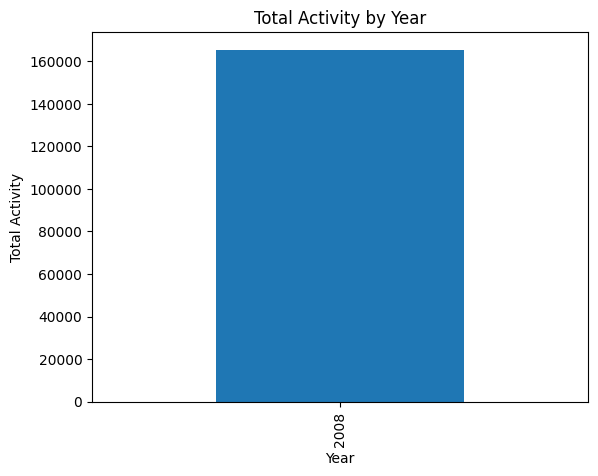

In [ ]:
year_sales = df.groupby("year").size()

year_sales.plot(kind="bar")

plt.title("Total Activity by Year")
plt.xlabel("Year")
plt.ylabel("Total Activity")

plt.show()

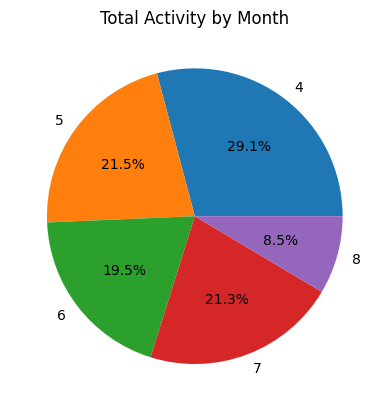

In [ ]:
month_sales = df.groupby("month").size()

plt.pie(month_sales, labels=month_sales.index, autopct="%1.1f%%")

plt.title("Total Activity by Month")
plt.show()

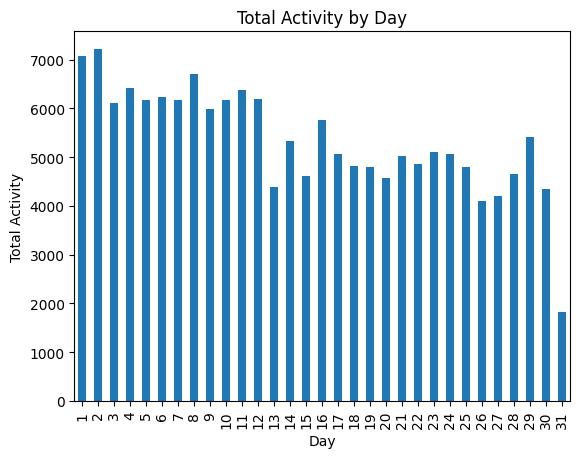

In [ ]:
day_sales = df.groupby("day").size()

day_sales.plot(kind="bar")

plt.title("Total Activity by Day")
plt.xlabel("Day")
plt.ylabel("Total Activity")

plt.show()

## Most attention product categories

In [ ]:
category_counts = df["page 1 (main category)"].value_counts()

category_counts

,count
page 1 (main category),
1,49742
4,38747
3,38577
2,38408


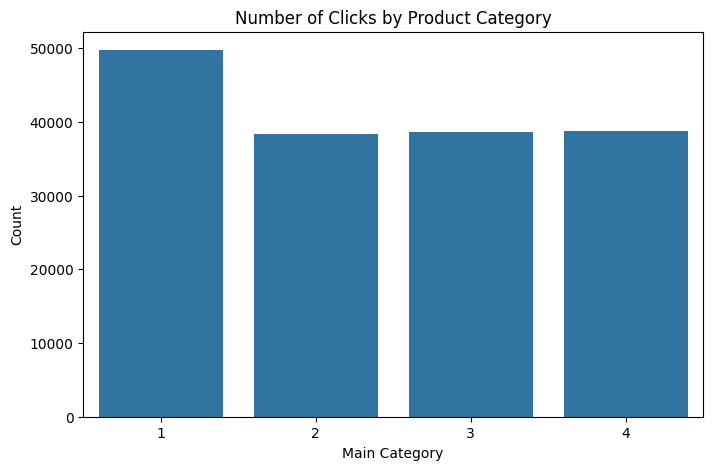

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="page 1 (main category)"
)

plt.title("Number of Clicks by Product Category")
plt.xlabel("Main Category")
plt.ylabel("Count")

plt.show()

## Most clicked pages

In [ ]:
page_counts = df["page"].value_counts().sort_index()

page_counts

,count
page,
1,93452
2,41037
3,19301
4,8861
5,2823


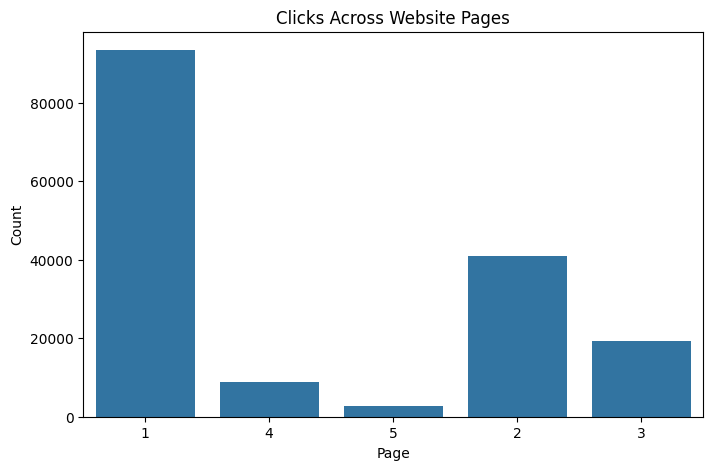

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="page"
)

plt.title("Clicks Across Website Pages")
plt.xlabel("Page")
plt.ylabel("Count")

plt.show()

## Product affect user behaviour

- price

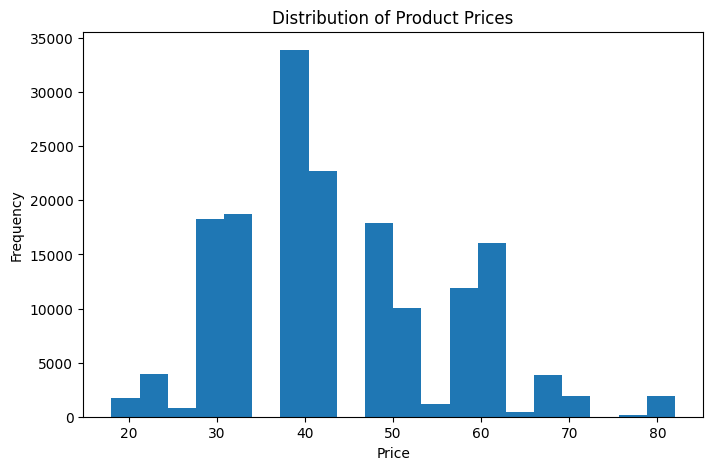

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df["price"], bins=20)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

- click order

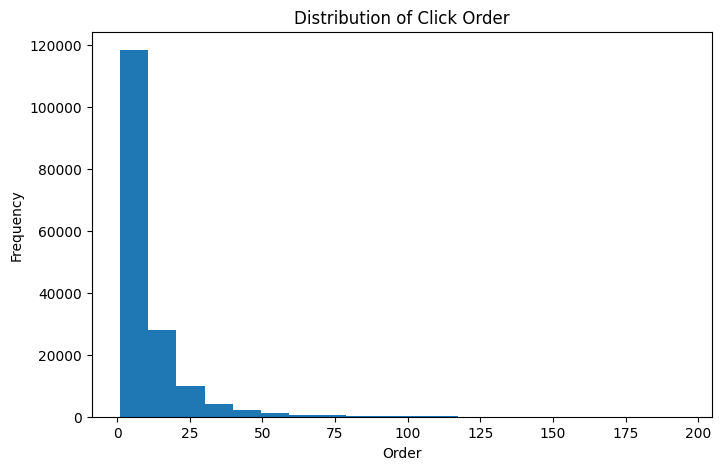

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df["order"], bins=20)

plt.title("Distribution of Click Order")
plt.xlabel("Order")
plt.ylabel("Frequency")

plt.show()

- price vs order

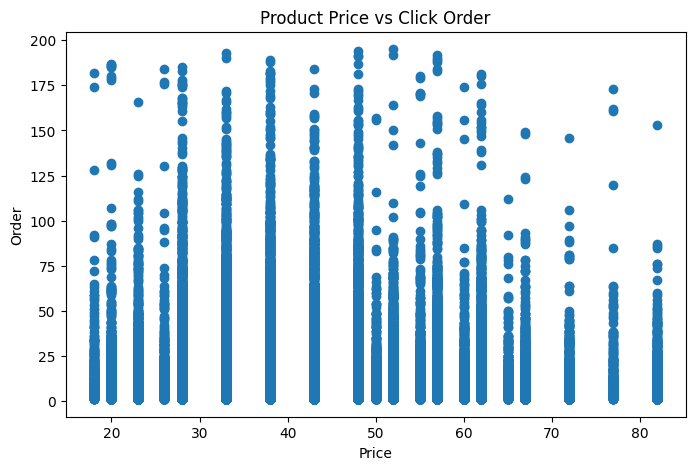

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["price"],
    df["order"],
)

plt.title("Product Price vs Click Order")
plt.xlabel("Price")
plt.ylabel("Order")

plt.show()

- page vs price

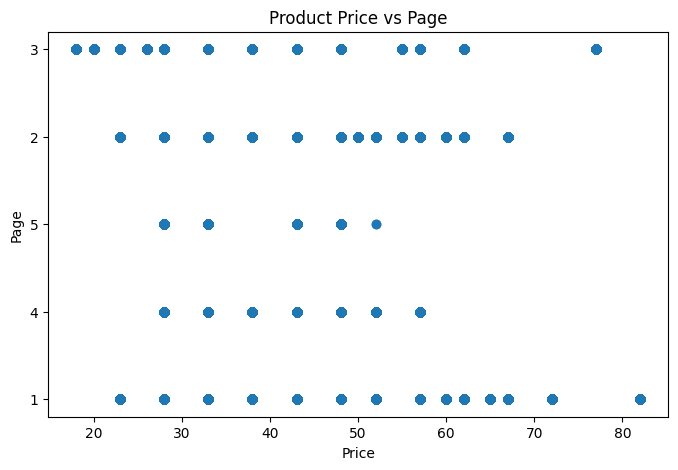

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["price"],
    df["page"],
)

plt.title("Product Price vs Page")
plt.xlabel("Price")
plt.ylabel("Page")

plt.show()

- price by main category

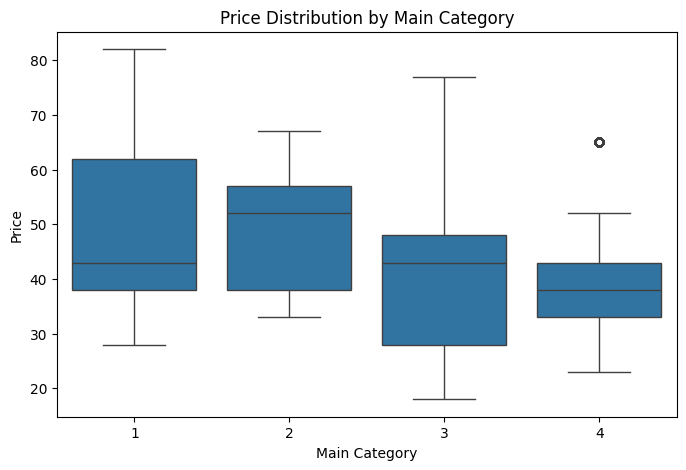

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="page 1 (main category)",
    y="price"
)

plt.title("Price Distribution by Main Category")
plt.xlabel("Main Category")
plt.ylabel("Price")

plt.show()

- order by main category

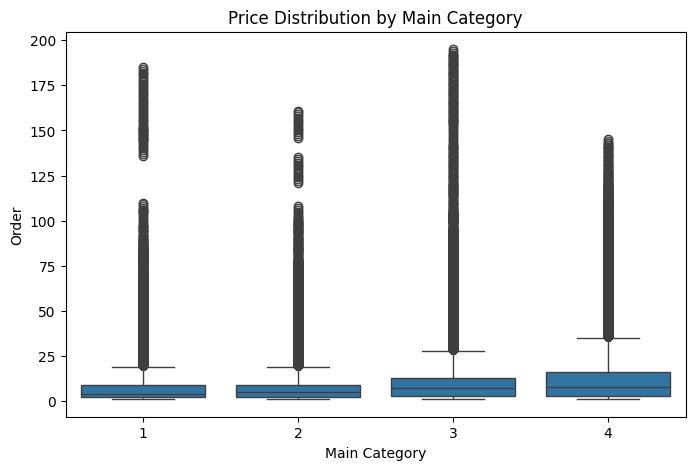

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="page 1 (main category)",
    y="order"
)

plt.title("Price Distribution by Main Category")
plt.xlabel("Main Category")
plt.ylabel("Order")

plt.show()

## Countries generate most activity

In [ ]:
country_counts = df["country"].value_counts()

country_counts.head(10)

,count
country,
29,133963
9,18003
24,4091
46,2522
44,1385
16,834
21,811
34,716
41,684


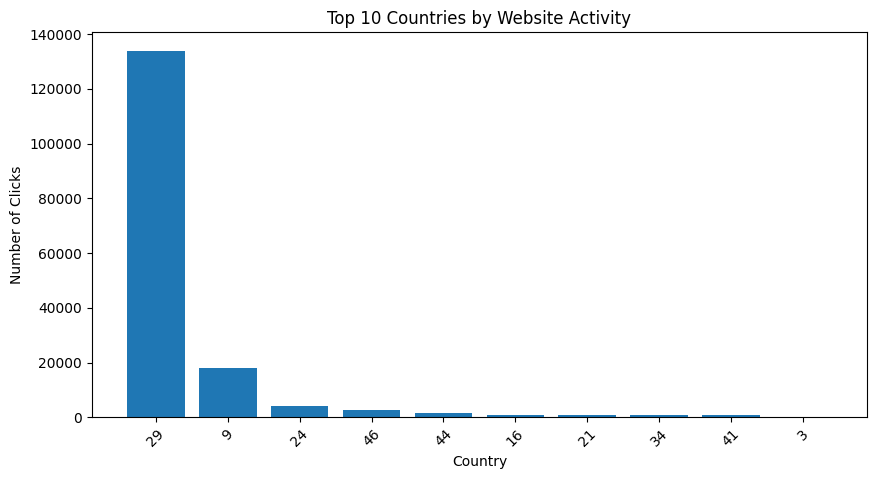

In [ ]:
plt.figure(figsize=(10,5))

plt.bar(country_counts.head(10).index.astype(str), country_counts.head(10).values)

plt.title("Top 10 Countries by Website Activity")
plt.xlabel("Country")
plt.ylabel("Number of Clicks")

plt.xticks(rotation=45)

plt.show()

- Most frequently visited locations

In [ ]:
location_counts = df["location"].value_counts()

location_counts

,count
location,
1,34532
2,33383
5,27783
4,27377
3,21656
6,20743


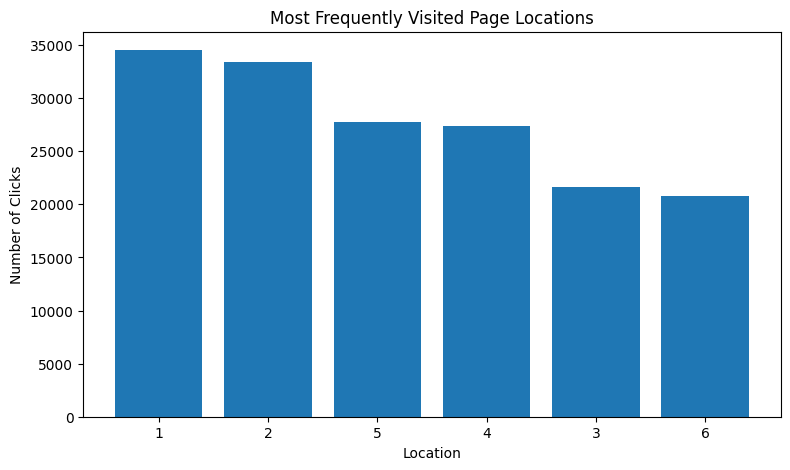

In [ ]:
plt.figure(figsize=(9,5))

plt.bar(location_counts.index.astype(str), location_counts.values)

plt.title("Most Frequently Visited Page Locations")
plt.xlabel("Location")
plt.ylabel("Number of Clicks")

plt.show()

## Difference in product categories

In [ ]:
category_price = df.groupby(
    "page 1 (main category)"
)["price"].mean()

category_price

,price
page 1 (main category),
1,46.714889
2,51.192434
3,40.291728
4,36.233799


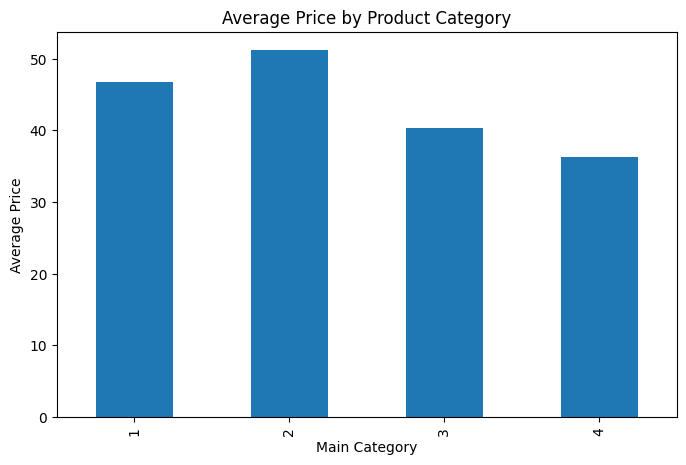

In [ ]:
plt.figure(figsize=(8,5))

category_price.plot(kind="bar")

plt.title("Average Price by Product Category")
plt.xlabel("Main Category")
plt.ylabel("Average Price")

plt.show()

- category vs page

## Browsing and purchasing

- category vs avg price

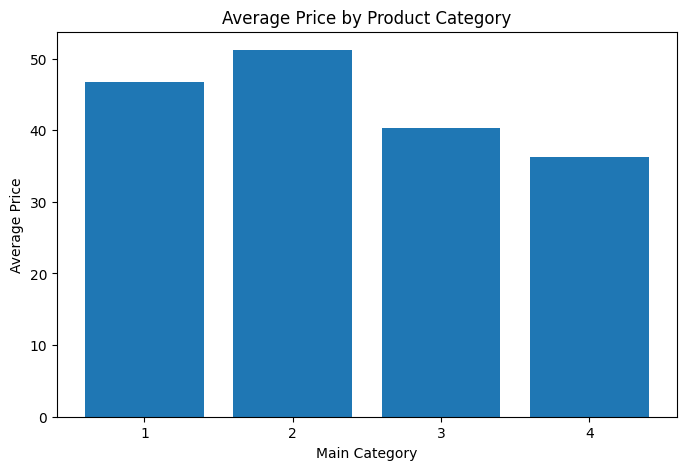

In [ ]:
category_price = df.groupby("page 1 (main category)")["price"].mean()

plt.figure(figsize=(8,5))
plt.bar(category_price.index, category_price.values)
plt.title("Average Price by Product Category")
plt.xlabel("Main Category")
plt.ylabel("Average Price")
plt.show()

- time chart

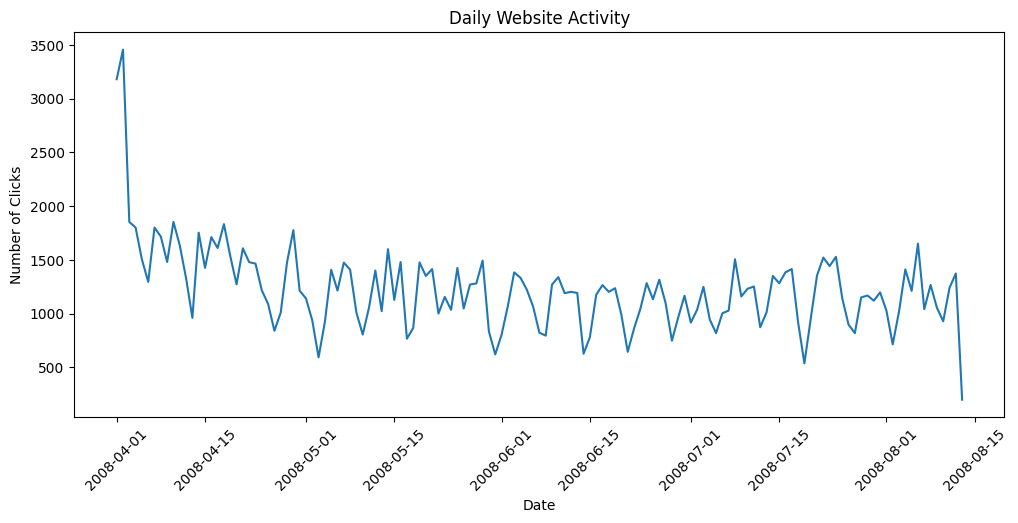

In [ ]:
daily_activity = df.groupby("date").size()
plt.figure(figsize=(12,5))
plt.plot(daily_activity.index, daily_activity.values)
plt.title("Daily Website Activity")
plt.xlabel("Date")
plt.ylabel("Number of Clicks")
plt.xticks(rotation=45)
plt.show()

## Patterns Related to Customer Conversion

- page vs average price

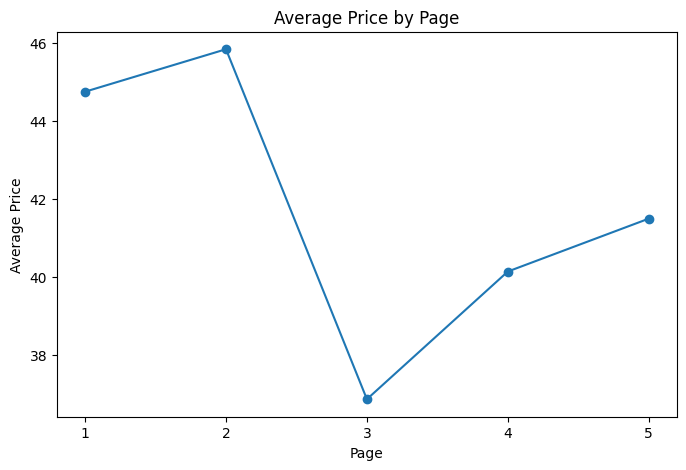

In [ ]:
page_price = df.groupby("page")["price"].mean()

plt.figure(figsize=(8,5))
plt.plot(page_price.index, page_price.values, marker="o")
plt.title("Average Price by Page")
plt.xlabel("Page")
plt.ylabel("Average Price")
plt.show()

- page vs average order

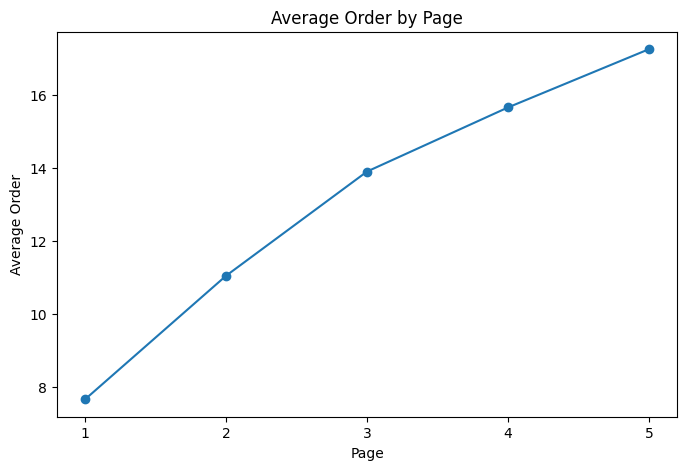

In [ ]:
page_order = df.groupby("page")["order"].mean()

plt.figure(figsize=(8,5))
plt.plot(page_order.index, page_order.values, marker="o")
plt.title("Average Order by Page")
plt.xlabel("Page")
plt.ylabel("Average Order")
plt.show()

- product category vs page activity

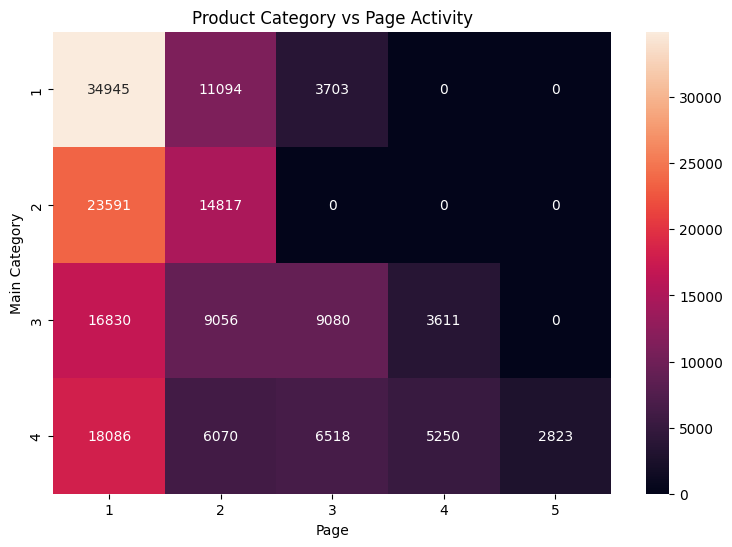

In [ ]:
category_page = pd.crosstab(
    df["page 1 (main category)"],
    df["page"]
)

plt.figure(figsize=(9,6))
sns.heatmap(category_page, annot=True, fmt="d")
plt.title("Product Category vs Page Activity")
plt.xlabel("Page")
plt.ylabel("Main Category")
plt.show()

## Unusual user behaviour or outliers

- price outliers

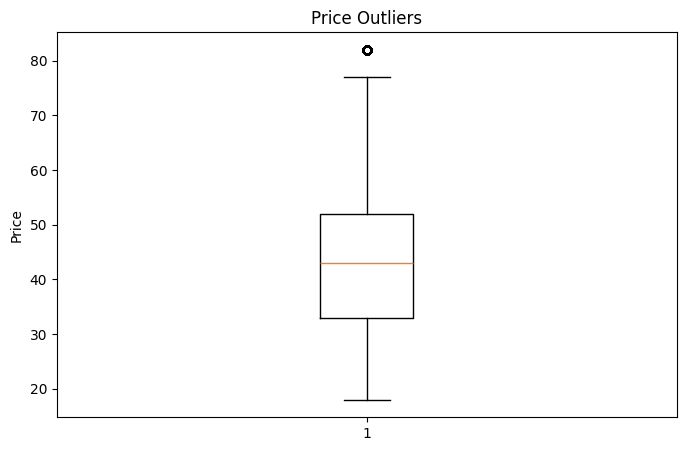

In [ ]:
plt.figure(figsize=(8,5))

plt.boxplot(df["price"])

plt.title("Price Outliers")
plt.ylabel("Price")

plt.show()

- order outliers

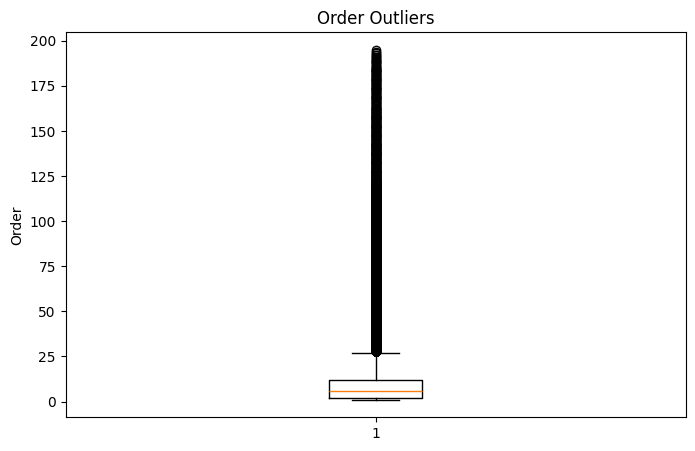

In [ ]:
plt.figure(figsize=(8,5))

plt.boxplot(df["order"])

plt.title("Order Outliers")
plt.ylabel("Order")

plt.show()



## Insights

* **Product Categories:** Some product categories receive more clicks than others. This shows that users are more interested in certain categories.

* **Website Pages:** Some pages get more clicks, which means they attract more user attention. These pages should be kept easy to use and navigate.

* **Product Price:** Product prices are different across categories. The price and order graphs help to understand whether price has any visible effect on user behaviour.

* **Countries:** Website activity is higher in some countries than others. The top countries can be targeted for better marketing and promotions.

* **Page Locations:** Some website locations receive more clicks than others. Popular locations can be given more importance while less-used locations can be improved.

* **Product Categories and Pages:** Different categories show different levels of activity across pages. This can help understand which categories and pages work better together.

* **Browsing Behaviour:** Daily activity shows that website activity changes over time. High-activity periods can be useful for promotions and marketing.

* **Customer Conversion:** Page activity, price, order, and category activity may be related to customer behaviour. However, this analysis shows patterns and does not prove that these variables directly cause conversion.

* **Outliers:** The price and order boxplots show unusual values, while session activity shows that some sessions have much more activity than others. These unusual cases may represent highly active users or unusual behaviour.

## Recommendations

1. Promote categories that receive more user attention.
2. Improve pages and locations that receive fewer clicks.
3. Use price and category information to plan suitable offers.
4. Focus marketing efforts on countries with higher activity.
5. Study high-activity sessions to understand user behaviour.
6. Compare browsing activity with actual purchases to understand conversion better.

## Limitations

* The dataset mainly shows browsing and click activity, not complete purchase information.
* The analysis shows relationships and patterns but does not prove cause and effect.
* Some outliers were identified but not investigated individually.
* More information such as customer details, discounts, device type, and actual purchase data could provide better insights.

## Conclusion

This EDA helped identify important patterns in customer browsing behaviour based on categories, pages, price, country, and sessions. These findings can help a business improve its website, marketing, and product strategy.
